# Mobile Game Player Spending Segmentation
## Data Cleaning and Preparation

### Project objective
NovaPlay Studios operates a free-to-play mobile game and uses in-app purchases as a key revenue stream. The business objective is to increase IAP revenue by **15% within three months of deploying the predictive ML model** through more relevant player offers. This project prepares demographic and early-gameplay data for a supervised model that predicts a new player's likely spending segment within the first **30-day period**: **Minnow** (low or no spending), **Dolphin** (moderate spending), or **Whale** (high spending), so the marketing team can tailor offers before month-end.

### Purpose of this notebook
Prepare and quality-check the player dataset before modeling.The cleaned output is **`02_clean_data.csv`**. `UserID` is retained for record checks, not as a model feature. `InAppPurchaseAmount` is retained for data-quality review, not as a predictor of a segment defined by spending.

## How to run this notebook

1. Run `01_data_generation.ipynb` and download **`mobile_game_players_expanded_dirty.csv`**.
2. Upload that file into the same Google Colab session (Files → Upload).
3. Run these cells from top to bottom; the final cell saves and downloads **`02_clean_data.csv`**.



## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if hasattr(value, 'to_string') else value)

INPUT_FILE = 'mobile_game_players_expanded_dirty.csv'
OUTPUT_FILE = '02_clean_data.csv'
REFERENCE_DATE = pd.Timestamp('2026-11-14')


## 2. Load the file and keep a before-cleaning copy

In [2]:
df = pd.read_csv(INPUT_FILE)
raw = df.copy(deep=True)

print(f'Rows: {len(df):,}')
print(f'Columns: {df.shape[1]}')
print(f'Exact duplicate rows: {int(df.duplicated().sum()):,}')
print(f'Missing cells: {int(df.isna().sum().sum()):,}')
display(df.head())


Rows: 250,000
Columns: 23
Exact duplicate rows: 2,500
Missing cells: 219,269


,UserID,Age,Gender,Country,Device,GameGenre,SessionCount,AverageSessionLength,SpendingSegment,InAppPurchaseAmount,...,AcquisitionChannel,InstallDate,ActiveDays30d,PlayerLevel30d,AdsWatched30d,SocialActions30d,GuildMember,PushNotificationsOptIn,PurchaseCount30d,WinRate
0,c9889ab0-9cfc-4a75-acd9-5eab1df0015c,49.0,Male,Norway,Android,Battle Royale,9.0,12.83,Minnow,11.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,7c9e413c-ecca-45f2-a780-2826a07952a2,15.0,Male,Switzerland,iOS,Action RPG,11.0,19.39,Minnow,6.37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,fd61e419-1a92-4f43-a8c7-135842ad328a,23.0,Male,China,Android,Fighting,9.0,8.87,Minnow,15.81,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,bdb7f6d1-ff9a-468c-afe7-43f32a94293e,31.0,Male,Mexico,Android,Racing,12.0,19.56,Minnow,13.49,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,aa7eec14-4846-47b9-b879-9c98038cda04,37.0,Female,India,Android,Battle Royale,10.0,15.23,Minnow,10.86,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Why this step?** We keep an unchanged copy (`raw`) so the notebook can compare missing values, segment shares, and numeric distributions before and after cleaning.


## 3. Review missing values before cleaning

In [3]:
missing_before = raw.isna().sum().sort_values(ascending=False)
missing_before = missing_before[missing_before > 0]
print('Columns with missing values:')
display(missing_before.to_frame('Missing rows'))


Columns with missing values:


,Missing rows
FirstPurchaseDaysAfterInstall,39543
PaymentMethod,21847
LastPurchaseDate,18318
AcquisitionChannel,15392
Country,13440
Age,10900
AverageSessionLength,9755
Gender,9350
InstallDate,7987
SocialActions30d,6765


**Why this step?** This identifies which fields need attention and gives a baseline for the missing-values comparison chart later.


## 4. Remove exact duplicate records

In [4]:
duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
print(f'Exact duplicate rows removed: {duplicates_removed:,}')
print(f'Rows remaining: {len(df):,}')


Exact duplicate rows removed: 2,500
Rows remaining: 247,500


**Why this step?** Exact copies can over-represent some players and distort summaries or model evaluation. Only fully identical rows are removed.


## 5. Standardize category labels

In [5]:
def tidy_text(series):
    return series.astype('string').str.strip()

# Standard capitalization for simple yes/no and gender values.
for col in ['Gender', 'GuildMember', 'PushNotificationsOptIn']:
    df[col] = tidy_text(df[col]).str.title()

# Map known spelling and capitalization variants to one label.
category_maps = {
    'Device': {'android':'Android', 'ios':'iOS'},
    'Country': {'uae':'UAE','united arab emirates':'UAE','usa':'USA','united states':'USA','uk':'UK','united kingdom':'UK'},
    'GameGenre': {'action rpg':'Action RPG','battleroyale':'Battle Royale','battle royale':'Battle Royale','moba':'MOBA','mmorpg':'MMORPG'},
    'PaymentMethod': {'paypal':'PayPal','creditcard':'Credit Card','credit card':'Credit Card','googlepay':'Google Pay','google pay':'Google Pay','apple pay':'Apple Pay','gift card':'Gift Card','debit card':'Debit Card','carrier billing':'Carrier Billing'},
    'AcquisitionChannel': {'organic':'Organic','paid social':'Paid Social','search ads':'Search Ads','cross-promotion':'Cross-promotion','referral':'Referral','influencer':'Influencer'}
}
for col, mapping in category_maps.items():
    original = tidy_text(df[col])
    df[col] = original.str.lower().map(mapping).fillna(original.str.title())

# Standardize the target labels.
target_key = tidy_text(df['SpendingSegment']).str.lower()
df['SpendingSegment'] = target_key.map({'minnow':'Minnow','dolphin':'Dolphin','whale':'Whale'})
invalid_target_rows = int(df['SpendingSegment'].isna().sum())
if invalid_target_rows:
    df = df.dropna(subset=['SpendingSegment']).copy()

print(f'Rows removed for missing/invalid target: {invalid_target_rows:,}')
print('Standardized target labels:', sorted(df['SpendingSegment'].unique()))


Rows removed for missing/invalid target: 0
Standardized target labels: ['Dolphin', 'Minnow', 'Whale']


**Why this step?** Values such as `android`/`Android` and `DOLPHIN`/`Dolphin` should be treated as the same category. A row without a valid target cannot train a supervised classifier, so such rows are counted and removed.


## 6. Convert session duration and purchase amount

In [6]:
# Convert durations to minutes. Example: 600 sec becomes 10 minutes.
duration_text = tidy_text(df['AverageSessionLength'])
seconds_mask = duration_text.str.contains(r'\bsec\b', case=False, na=False)
duration_text = duration_text.str.replace(r'\s*sec\s*$', '', case=False, regex=True).str.strip()
df['AverageSessionLength'] = pd.to_numeric(duration_text, errors='coerce')
df.loc[seconds_mask, 'AverageSessionLength'] /= 60

# Remove currency symbols and convert to numbers.
amount_text = tidy_text(df['InAppPurchaseAmount']).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
df['InAppPurchaseAmount'] = pd.to_numeric(amount_text, errors='coerce')

print('Values with seconds converted:', int(seconds_mask.sum()))
print('AverageSessionLength is now measured in minutes.')
print('InAppPurchaseAmount is now numeric.')


Values with seconds converted: 2933
AverageSessionLength is now measured in minutes.
InAppPurchaseAmount is now numeric.


**Why this step?** Numeric values are needed for statistical summaries and modeling. Removing `sec` alone would leave the wrong unit, so seconds are divided by 60; the dollar sign is formatting and is removed without changing the amount.


## 7. Parse dates into one consistent format

In [7]:
def parse_dates(series):
    text = tidy_text(series)
    parsed = pd.Series(pd.NaT, index=series.index, dtype='datetime64[ns]')
    formats = ['%Y-%m-%d', '%Y-%m-%d %H:%M:%S', '%m/%d/%Y', '%d-%m-%Y']
    for date_format in formats:
        parsed = parsed.fillna(pd.to_datetime(text, format=date_format, errors='coerce'))
    return parsed

for col in ['InstallDate', 'LastPurchaseDate']:
    df[col] = parse_dates(df[col])

print('Date columns converted:', ['InstallDate', 'LastPurchaseDate'])


Date columns converted: ['InstallDate', 'LastPurchaseDate']


**Why this step?** Mixed date formats are hard to sort, compare, or use in calculations. The parser accepts the formats in the file; unreadable values become missing so they can be handled later.


## 8. Convert numeric columns and flag impossible values

In [8]:
numeric_cols = [
    'Age','SessionCount','AverageSessionLength','InAppPurchaseAmount',
    'FirstPurchaseDaysAfterInstall','ActiveDays30d','PlayerLevel30d',
    'AdsWatched30d','SocialActions30d','PurchaseCount30d','WinRate'
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

invalid_rules = {
    'Age': (df['Age'] < 13) | (df['Age'] > 100),
    'SessionCount': df['SessionCount'] < 0,
    'AverageSessionLength': df['AverageSessionLength'] < 0,
    'InAppPurchaseAmount': df['InAppPurchaseAmount'] < 0,
    'FirstPurchaseDaysAfterInstall': df['FirstPurchaseDaysAfterInstall'] < 0,
    'ActiveDays30d': (df['ActiveDays30d'] < 0) | (df['ActiveDays30d'] > 30),
    'PlayerLevel30d': df['PlayerLevel30d'] < 1,
    'AdsWatched30d': df['AdsWatched30d'] < 0,
    'SocialActions30d': df['SocialActions30d'] < 0,
    'PurchaseCount30d': df['PurchaseCount30d'] < 0,
    'WinRate': (df['WinRate'] < 0) | (df['WinRate'] > 1)
}
invalid_counts = {}
for col, mask in invalid_rules.items():
    invalid_counts[col] = int(mask.sum())
    df.loc[mask, col] = np.nan

display(pd.Series(invalid_counts, name='Invalid values marked missing').to_frame())


,Invalid values marked missing
Age,733
SessionCount,488
AverageSessionLength,0
InAppPurchaseAmount,0
FirstPurchaseDaysAfterInstall,0
ActiveDays30d,0
PlayerLevel30d,0
AdsWatched30d,0
SocialActions30d,0
PurchaseCount30d,0


**Why this step?** Negative ages/session counts and win rates outside 0–1 are impossible as recorded. We mark them missing instead of changing a negative value to a positive one, because the true value is unknown.


## 9. Check and flag impossible dates

In [9]:
future_dates = (df['InstallDate'] > REFERENCE_DATE) | (df['LastPurchaseDate'] > REFERENCE_DATE)
future_date_count = int(future_dates.sum())
df.loc[future_dates, ['InstallDate','LastPurchaseDate']] = pd.NaT

install_after_purchase = df['InstallDate'] > df['LastPurchaseDate']
wrong_order_count = int(install_after_purchase.sum())
df.loc[install_after_purchase, 'InstallDate'] = pd.NaT

print(f'Rows with future dates marked missing: {future_date_count:,}')
print(f'Install dates later than last purchase marked missing: {wrong_order_count:,}')


Rows with future dates marked missing: 1
Install dates later than last purchase marked missing: 0


**Why this step?** A date after the project reference date, or an installation date after a recorded purchase, conflicts with the expected event order. We mark the problematic date missing so it can be imputed consistently.


## 10. Fill missing numeric values

In [10]:
imputed_counts = {}
for col in numeric_cols:
    count = int(df[col].isna().sum())
    if count:
        median_value = df[col].median()
        if pd.isna(median_value):
            median_value = 0
        df[col] = df[col].fillna(median_value)
        imputed_counts[col] = count

display(pd.Series(imputed_counts, name='Numeric values filled').to_frame())


,Numeric values filled
Age,11530
SessionCount,5360
AverageSessionLength,9764
InAppPurchaseAmount,6195
FirstPurchaseDaysAfterInstall,39186
ActiveDays30d,6691
PlayerLevel30d,6691
AdsWatched30d,6691
SocialActions30d,6691
PurchaseCount30d,6691


**Why this step?** The median is less affected by unusually high or low values than the mean. It fills numeric gaps while preserving the overall typical value; the number filled is recorded for transparency.


## 11. Fill missing category values

In [11]:
category_cols = [
    'Gender','Country','Device','GameGenre','PaymentMethod',
    'AcquisitionChannel','GuildMember','PushNotificationsOptIn'
]
for col in category_cols:
    count = int(df[col].isna().sum())
    if count:
        modes = df[col].mode(dropna=True)
        fill_value = modes.iloc[0] if len(modes) else 'Unknown'
        df[col] = df[col].fillna(fill_value)
        imputed_counts[col] = count

display(pd.Series({c: imputed_counts[c] for c in category_cols if c in imputed_counts}, name='Category values filled').to_frame())


,Category values filled
Gender,9249
Country,13312
Device,4946
GameGenre,4923
PaymentMethod,21630
AcquisitionChannel,15247
GuildMember,5468
PushNotificationsOptIn,5468


**Why this step?** Missing category cells are filled with the most frequent valid category so the file has no blank category cells. This is an estimate, not a recovered original response.


## 12. Fill missing dates and keep date order valid

In [12]:
date_fill_counts = {}
for col in ['InstallDate','LastPurchaseDate']:
    count = int(df[col].isna().sum())
    if count:
        valid_dates = df[col].dropna()
        median_ns = int(valid_dates.astype('int64').median()) if len(valid_dates) else int(REFERENCE_DATE.value)
        df[col] = df[col].fillna(pd.Timestamp(median_ns))
        date_fill_counts[col] = count

# If independent date filling creates a reversed event order, adjust InstallDate
# to precede LastPurchaseDate by the median observed gap.
reversed_dates = df['InstallDate'] > df['LastPurchaseDate']
if reversed_dates.any():
    valid_gaps = (df.loc[~reversed_dates, 'LastPurchaseDate'] - df.loc[~reversed_dates, 'InstallDate']).dt.days
    median_gap = int(valid_gaps[valid_gaps >= 0].median()) if (valid_gaps >= 0).any() else 30
    df.loc[reversed_dates, 'InstallDate'] = df.loc[reversed_dates, 'LastPurchaseDate'] - pd.to_timedelta(median_gap, unit='D')

display(pd.Series(date_fill_counts, name='Date values filled').to_frame())
print('InstallDate after LastPurchaseDate:', int((df['InstallDate'] > df['LastPurchaseDate']).sum()))


,Date values filled
InstallDate,7914
LastPurchaseDate,18143


InstallDate after LastPurchaseDate: 0


**Why this step?** Date fields need a valid datetime value for sorting and time-based analysis. Median dates fill gaps, and the final check ensures installation does not occur after the last purchase.


## 13. Compare missing values before and after

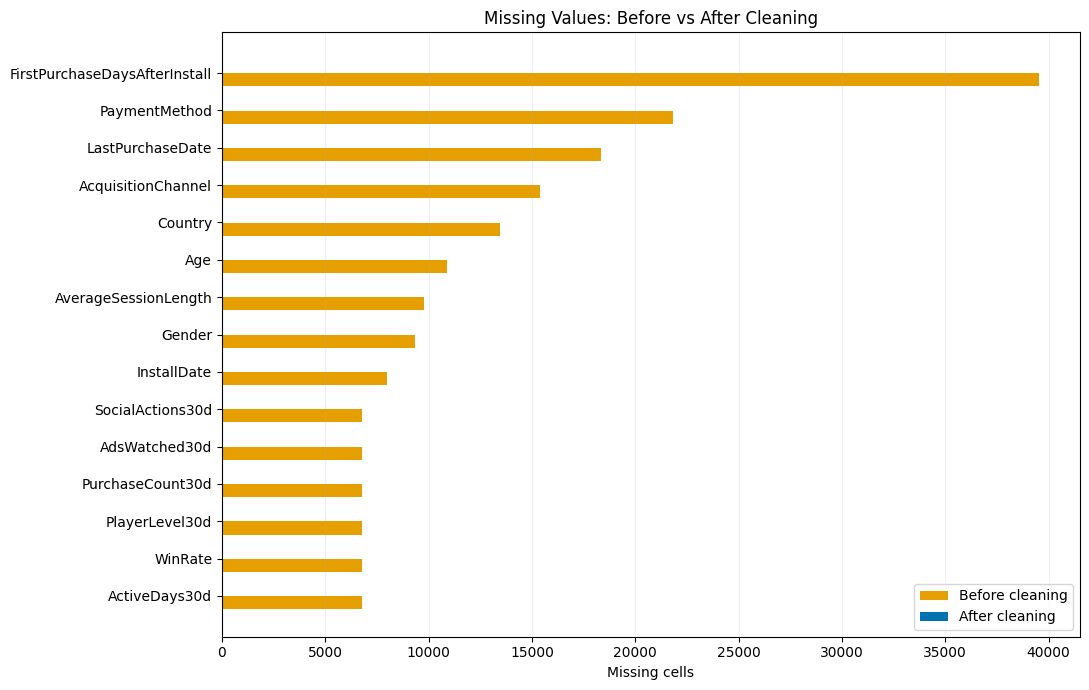

In [13]:
missing_compare = pd.DataFrame({'Before': raw.isna().sum(), 'After': df.isna().sum()})
plot_missing = missing_compare.sort_values('Before').tail(15)

fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(plot_missing))
ax.barh(y - .18, plot_missing['Before'], height=.35, label='Before cleaning', color='#e69f00')
ax.barh(y + .18, plot_missing['After'], height=.35, label='After cleaning', color='#0072b2')
ax.set_yticks(y)
ax.set_yticklabels(plot_missing.index)
ax.set_xlabel('Missing cells')
ax.set_title('Missing Values: Before vs After Cleaning')
ax.legend()
ax.grid(axis='x', alpha=.2)
fig.tight_layout()
fig.savefig('cleaning_missing_values_comparison.png', dpi=160, bbox_inches='tight')
plt.show()


**How to read this chart:** Orange bars show missing cells before cleaning; blue bars show missing cells after cleaning. The blue bars should be zero because gaps were imputed.


## 14. Compare spending-segment distribution

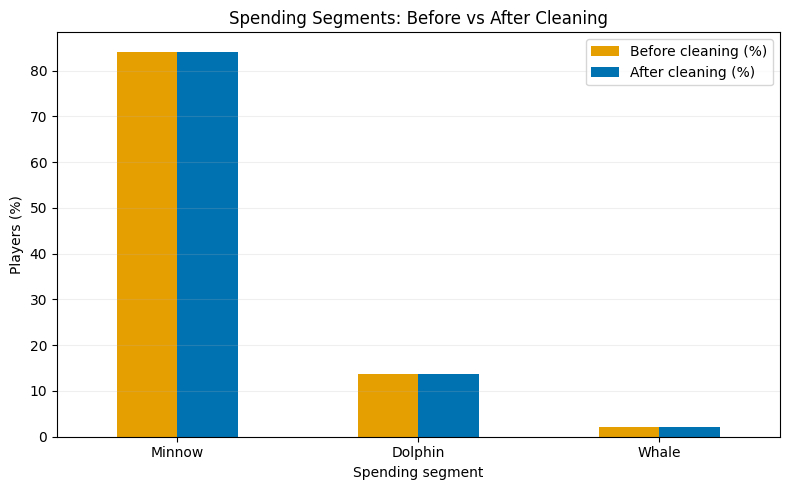

,Before cleaning (%),After cleaning (%)
SpendingSegment,,
Minnow,84.16,84.17
Dolphin,13.61,13.60
Whale,2.23,2.22


In [14]:
def normalize_segments(series):
    return series.astype('string').str.strip().str.lower().map({'minnow':'Minnow','dolphin':'Dolphin','whale':'Whale'})

before_segments = normalize_segments(raw['SpendingSegment']).value_counts(normalize=True).reindex(['Minnow','Dolphin','Whale'], fill_value=0) * 100
after_segments = df['SpendingSegment'].value_counts(normalize=True).reindex(['Minnow','Dolphin','Whale'], fill_value=0) * 100
segment_compare = pd.DataFrame({'Before cleaning (%)': before_segments, 'After cleaning (%)': after_segments})

ax = segment_compare.plot(kind='bar', figsize=(8,5), color=['#e69f00','#0072b2'])
ax.set_title('Spending Segments: Before vs After Cleaning')
ax.set_ylabel('Players (%)')
ax.set_xlabel('Spending segment')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.savefig('cleaning_segment_comparison.png', dpi=160, bbox_inches='tight')
plt.show()
display(segment_compare.round(2))


**Why this chart?** Duplicate removal can slightly change class proportions. This comparison confirms that the Minnow/Dolphin/Whale mix remains broadly stable after cleaning.


## 15. Compare key numeric fields

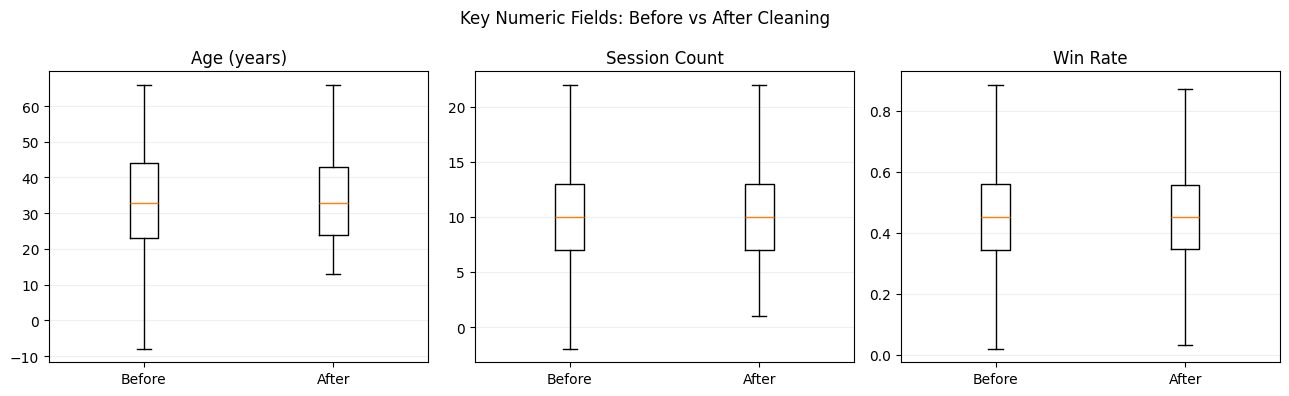

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, title in zip(axes, ['Age','SessionCount','WinRate'], ['Age (years)','Session Count','Win Rate']):
    before_values = pd.to_numeric(raw[col], errors='coerce').dropna()
    after_values = df[col].dropna()
    ax.boxplot([before_values, after_values], tick_labels=['Before','After'], showfliers=False)
    ax.set_title(title)
    ax.grid(axis='y', alpha=.2)
fig.suptitle('Key Numeric Fields: Before vs After Cleaning')
fig.tight_layout()
fig.savefig('cleaning_numeric_comparison.png', dpi=160, bbox_inches='tight')
plt.show()


**How to read this chart:** The boxes compare the central spread before and after cleaning. The impossible negative age/session values are no longer present, and missing values have been filled. Outliers are hidden from the plot for readability, not deleted from the dataset.


## 16. Final checks and save the cleaned file

In [16]:
# Verify completeness and core constraints before saving.
assert int(df.isna().sum().sum()) == 0, 'Missing cells remain.'
assert int(df.duplicated().sum()) == 0, 'Duplicate rows remain.'
assert df['SpendingSegment'].isin(['Minnow','Dolphin','Whale']).all(), 'Unexpected target label found.'
assert df['WinRate'].between(0, 1).all(), 'WinRate outside 0-1 remains.'

print(f'Final size: {len(df):,} rows × {df.shape[1]} columns')
print('Missing cells:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
print('InstallDate after LastPurchaseDate:', int((df['InstallDate'] > df['LastPurchaseDate']).sum()))

segment_summary = df['SpendingSegment'].value_counts().reindex(['Minnow','Dolphin','Whale'], fill_value=0).to_frame('Players')
segment_summary['Percent'] = (segment_summary['Players'] / len(df) * 100).round(2)
display(segment_summary)

df.to_csv(OUTPUT_FILE, index=False)
print(f'Saved: {OUTPUT_FILE}')


Final size: 247,500 rows × 23 columns
Missing cells: 0
Duplicate rows: 0
InstallDate after LastPurchaseDate: 0


,Players,Percent
SpendingSegment,,
Minnow,208328,84.17
Dolphin,33670,13.60
Whale,5502,2.22


Saved: 02_clean_data.csv


**Why these checks?** They verify that the exported file has no blanks or duplicate rows, contains only the three valid target labels, and has valid win rates. The segment table is a key result for the next modeling stage.


### Important modeling note

`UserID` is an identifier, not a predictor. `InAppPurchaseAmount` should not be used to predict a spending segment defined by spending. Review `PurchaseCount30d` carefully because it may reveal target-related information. For a rigorous model evaluation, fit imputation rules on the training data only after the train/test split.


In [17]:
# Optional download cell for Google Colab; in local Jupyter, the file is saved in this folder.
try:
    from google.colab import files
    files.download(OUTPUT_FILE)
except ImportError:
    print(f'Find {OUTPUT_FILE} in the current notebook folder.')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>